<a href="https://colab.research.google.com/github/lucassoaresdeoliveira07-afk/analise-reviews-simrmtc/blob/main/analise_reviews_simrmtc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# O que os usuários dizem do SiMRmtc?

Análise das avaliações do aplicativo **SiMRmtc** (transporte coletivo da Região Metropolitana de Goiânia) na Google Play Store.

- **Autor:** Lucas Soares
- **Início:** 04/11/2026
- **Pergunta:** quais são os principais motivos de satisfação e de insatisfação dos usuários?

**Etapas:** 1. Preparação do ambiente · 2. Coleta · 3. Qualidade dos dados · 4. Análise das notas · 5. Pré-processamento do texto · 6. Frequência de palavras

## 1. Preparação do ambiente

Instalação e importação das bibliotecas. A coleta usa a [`gplay-scraper`](https://github.com/Mohammedcha/gplay-scraper), que lê os dados públicos da Google Play sem precisar de chave de API.

In [22]:
!pip install -q gplay-scraper curl-cffi unidecode wordcloud

import re
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import nltk
from nltk import ngrams
from nltk.corpus import stopwords
from unidecode import unidecode
from wordcloud import WordCloud
from gplay_scraper import GPlayScraper, Config

nltk.download('stopwords', quiet=True)

# configurações da coleta: pausa entre requisições, tempo limite e tentativas
Config.RATE_LIMIT_DELAY = 2.0
Config.DEFAULT_TIMEOUT = 30
Config.DEFAULT_RETRY_COUNT = 5

scraper = GPlayScraper(http_client="curl_cffi")

## 2. Coleta

O identificador do app na Play Store é o *package name*, que aparece na URL da página depois de `id=`.

Primeiro, a ficha do aplicativo (nota média, instalações, versão etc.).

In [23]:
APP_ID = 'br.com.consorciormtc.amip002'

info_app = scraper.app_analyze(APP_ID, lang="pt", country="br")
info_app

{'appId': 'br.com.consorciormtc.amip002',
 'title': 'SiMRmtc',
 'summary': 'O SiMRmtc é o único que oferece um canal de relacionamento direto com a RMTC',
 'description': 'O aplicativo SiMRmtc é uma excelente ferramenta de mobilidade urbana, através dele você pode acompanhar o deslocamento dos veículos da Região Metropolitana de Goiânia em tempo real. O GPS do celular reconhece sua localização e mostra os pontos de ônibus próximos e os locais de venda de recarga do cartão Sitpass. \n\nAo clicar no ponto desejado aparecem os horários dos dois próximos veículos por linha que passarão por ali.\n\nAlém disso, o aplicativo oferece também o serviço planeje sua viagem, onde você pode, a partir da informação de um endereço de origem e de destino, descobrir as linhas de ônibus disponíveis para te conectar ao seu destino, com todo o detalhamento de horários das viagens, tempos de deslocamento, locais de embarque e desembarque e integrações com outras linhas, quando necessário.\n\nO SiMRmtc é o ú

Depois, as avaliações. Por privacidade, **nomes e fotos dos usuários não são coletados**: guardamos só nota, texto, votos de "útil", versão do app e data.

In [24]:
content = []

avaliacoes = scraper.reviews_analyze(
    APP_ID,
    count=10000,      # máximo de avaliações; a biblioteca devolve as que existirem
    sort="NEWEST",
    lang="pt",
    country="br"
)

for review in tqdm(avaliacoes):
    content.append({
        'reviewId': review.get('reviewId'),
        'score': review.get('score'),
        'content': review.get('content'),
        'thumbsUpCount': review.get('thumbsUpCount'),
        'appVersion': review.get('appVersion'),
        'at': review.get('at')
    })

print(len(content), "avaliações coletadas")

100%|██████████| 3885/3885 [00:00<00:00, 809079.99it/s]

3885 avaliações coletadas


## 3. Qualidade dos dados

Transformação em tabela, remoção de duplicadas, conversão da data e checagens básicas. O CSV é salvo para não precisar raspar de novo a cada sessão (para recarregar: `df = pd.read_csv('reviews_simrmtc.csv', parse_dates=['at'])`).

In [25]:
df = pd.DataFrame(content)
df = df.drop_duplicates(subset='reviewId')
df['at'] = pd.to_datetime(df['at'])

df.to_csv('reviews_simrmtc.csv', index=False, encoding='utf-8')

print(f'Linhas: {df.shape[0]} | Colunas: {df.shape[1]}')
print("Avaliação mais antiga:", df['at'].min().date())
print("Avaliação mais recente:", df['at'].max().date())
print("Textos nulos:", df['content'].isna().sum())
print("Textos vazios ou só com espaços:", (df['content'].str.strip() == "").sum())
print("reviewId duplicado:", df.duplicated(subset='reviewId').sum())

Linhas: 3885 | Colunas: 6
Avaliação mais antiga: 2015-03-20
Avaliação mais recente: 2026-11-09
Textos nulos: 2
Textos vazios ou só com espaços: 0
reviewId duplicado: 0


Há muitos textos repetidos com a mesma nota. Eles **não são duplicatas**: são avaliações curtas e comuns ("bom", "ótimo") escritas por pessoas diferentes, então são mantidas.

In [26]:
print("Mesmo texto e mesma nota:", df.duplicated(subset=['content', 'score']).sum())
df[df.duplicated(subset=['content', 'score'])]['content'].str.lower().value_counts().head(15)

Mesmo texto e mesma nota: 605


,count
content,
bom,138
muito bom,137
ótimo,94
otimo,35
top,19
excelente,17
ótima,14
boa,14
ok,10


## 4. Análise das notas

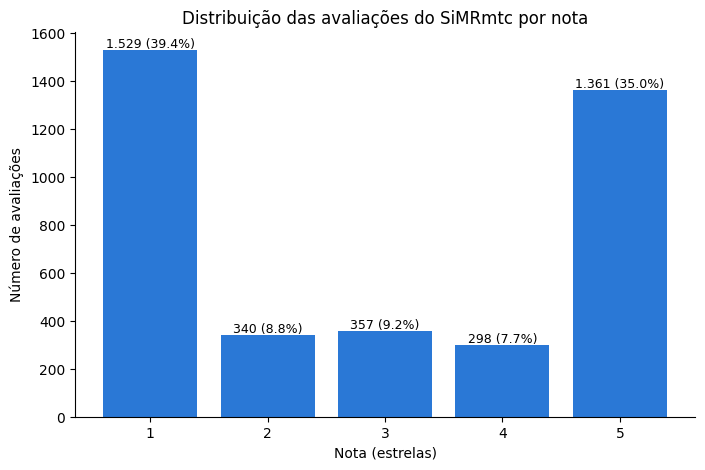

In [27]:
contagem = df['score'].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
percentual = (contagem / contagem.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(contagem.index, contagem.values, color="#2a78d6")
ax.bar_label(barras, labels=[f"{n:,} ({p}%)".replace(",", ".") for n, p in zip(contagem, percentual)], fontsize=9)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Nota (estrelas)")
ax.set_ylabel("Número de avaliações")
ax.set_title("Distribuição das avaliações do SiMRmtc por nota")
ax.spines[["top", "right"]].set_visible(False)
plt.savefig('distribuicao_notas.png', dpi=150, bbox_inches='tight')
plt.show()

**Leitura:** as notas são polarizadas. Quase 3 em cada 4 avaliações estão nos extremos (1★ ou 5★): os usuários ou aprovam ou rejeitam o app, com pouco meio-termo.

## 5. Pré-processamento do texto

Decisões tomadas:
- **Minúsculas e sem acento**, para "não", "nao" e "nào" virarem a mesma palavra (o mesmo para "ônibus" e "onibus").
- Remoção de links, números, pontuação e emojis.
- Remoção de *stopwords* (palavras sem significado, como "de", "que"), **mantendo as negações**: "não funciona" e "funciona" têm sentidos opostos.
- Remoção de palavras que aparecem em quase tudo e não dizem nada (ex.: "app", "aplicativo").

O texto original (`content`) é mantido, porque modelos como o BERT funcionam melhor com ele. O texto limpo vai em `content_limpo`.

In [28]:
stop_pt = {unidecode(p) for p in stopwords.words('portuguese')}
negacoes = {'nao', 'nem', 'nunca', 'nada', 'ninguem', 'sem'}
stop_extra = {'app', 'aplicativo', 'pra', 'pro', 'mto', 'vai', 'esta',
              'ter', 'ficar', 'poder', 'vez', 'todo'}   # verbos e palavras genéricas que subiram com a lematização
stop_final = (stop_pt - negacoes) | stop_extra

def limpar_texto(texto):
    if not isinstance(texto, str):
        return ''
    texto = unidecode(texto.lower())                  # minúsculo e sem acento
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)   # links
    texto = re.sub(r'\d+', ' ', texto)                # números
    texto = re.sub(r'[^a-z\s]', ' ', texto)           # pontuação e emojis
    palavras = [p for p in texto.split() if p not in stop_final and len(p) > 2]
    return ' '.join(palavras)

df = df.dropna(subset=['content'])
df['content_limpo'] = df['content'].apply(limpar_texto)
df[['content', 'content_limpo']].sample(10, random_state=42)

,content,content_limpo
1344,O PIOR aplicativo que já vi agente não conhece...,pior agente nao conhece horario onibus confuso
2637,bom,bom
3598,"Não faz o login, fica horas carregando e não f...",nao faz login fica horas carregando nao faz login
3615,"Funciona bem no meu Z-4, não trava e me dá os ...",funciona bem nao trava horarios corretos bom
1812,Muito ruim,ruim
2155,Muito lento,lento
721,"Olá bom dia !! Me de um suporte, ontem atualiz...",ola bom dia suporte ontem atualizei desde enta...
351,O app é bom e útil. Porém não permite salvar o...,bom util porem nao permite salvar pontos somen...
1221,Porque retiraram a página de favoritos? Era o ...,porque retiraram pagina favoritos facilitava h...
322,Esse aplicativo infelizmente não funciona. Par...,infelizmente nao funciona trabalhador estresse...


In [29]:
!python -m spacy download pt_core_news_sm -q
import spacy

# modelo de português; desligamos o que não usamos para ficar mais rápido
nlp = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])

# correções de lemas que o spaCy erra
correcoes = {'onibu': 'onibus', 'ônibu': 'ônibus', 'ameir': 'amar',
             'trar': 'travar', 'mau': 'pior'}

def lematizar(textos):
    resultado = []
    for doc in nlp.pipe(textos, batch_size=200):
        lemas = [correcoes.get(t.lemma_.lower(), t.lemma_.lower()) for t in doc]
        resultado.append(' '.join(lemas))
    return resultado

# 1º lematiza o texto original (com acento), 2º aplica a limpeza
df['content_lema'] = lematizar(df['content'].str.lower())
df['content_limpo'] = df['content_lema'].apply(limpar_texto)

df[['content', 'content_limpo']].sample(10, random_state=42)

✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


,content,content_limpo
1344,O PIOR aplicativo que já vi agente não conhece...,pior ver agente nao conhecer horario onibus co...
2637,bom,bom
3598,"Não faz o login, fica horas carregando e não f...",nao fazer login hora carregar nao fazer login
3615,"Funciona bem no meu Z-4, não trava e me dá os ...",funcionar bem nao travar dar horario correto bom
1812,Muito ruim,ruim
2155,Muito lento,lento
721,"Olá bom dia !! Me de um suporte, ontem atualiz...",ola bom dia suporte ontem atualizei desde enta...
351,O app é bom e útil. Porém não permite salvar o...,bom util porem nao permitir salvar ponto somen...
1221,Porque retiraram a página de favoritos? Era o ...,porque retirar pagina favorito facilitar hora ...
322,Esse aplicativo infelizmente não funciona. Par...,infelizmente nao funcionar trabalhador estress...


In [30]:
print("Mesmo texto e mesma nota:", df.duplicated(subset=['content_limpo', 'score']).sum())
df[df.duplicated(subset=['content_limpo', 'score'])]['content_limpo'].str.lower().value_counts().head(15)

Mesmo texto e mesma nota: 949


,count
content_limpo,
bom,550
otimo,44
,34
excelente,29
top,23
pessimo,22
gostar,21
nao funcionar,21
horrivel,17


Algumas avaliações ficam vazias depois da limpeza (só emojis, "ok", números). Elas saem das análises de frequência, mas **continuam** na análise das notas.

In [31]:
vazias = df[df['content_limpo'] == '']
print(len(vazias), "avaliações ficaram sem texto útil")
display(vazias[['content', 'score']].head(10))

df_texto = df[df['content_limpo'] != ''].copy()
print(len(df), "avaliações no total")
print(len(df_texto), "avaliações com texto útil para análise de frequência")

39 avaliações ficaram sem texto útil


,content,score
406,Ok,2
451,Ok,1
469,Ok,5
610,Está fora do ar,1
867,👍,5
996,👍,5
1015,E o que vc tem,2
1076,Ok,5
1100,Fica mais fora do ar,2
1281,Ok,4


3883 avaliações no total
3844 avaliações com texto útil para análise de frequência


In [32]:
df.head()

,reviewId,score,content,thumbsUpCount,appVersion,at,content_limpo,content_lema
0,ea174d96-40db-46e1-a066-cf21501151cb,1,os horários nunca batem com o horário do ônibu...,0,1.7.4,2026-11-09 17:29:44,horario nunca bater horario onibus horrivel,o horário nunca bater com o horário de o ônibu...
1,a59451d9-375a-4d7e-bd6e-828c9f1b7b37,1,O aplicativo é extremamente necessário. Mas se...,0,1.7.4,2026-11-09 16:38:18,extremamente necessario nao mostrar horario co...,o aplicativo ser extremamente necessário . mas...
2,0b554d67-9bc3-4e6a-baa9-d571862e765c,1,"Eu nunca vi um aplicativo que só da erro, só f...",0,1.7.4,2026-11-05 08:53:31,nunca ver erro funcionar querer,"eu nunca ver um aplicativo que só de o erro , ..."
3,163089fd-49b2-4f7c-b705-06c443fe496e,1,muito difícil acesso nos pontos de ônibus,0,1.7.4,2026-11-03 07:58:56,dificil acesso ponto onibus,muito difícil acesso em o ponto de ônibus
4,20f12b7b-532f-40c8-942d-99262a43f29e,3,"plmds, cadê as atualizações desse aplicativo? ...",0,1.7.4,2026-11-03 03:15:50,plmds cade atualizacao cada dia pior nao apare...,"plmds , cadê o atualização de esse aplicativo ..."


## 6. Frequência de palavras

A nuvem de palavras abre a conversa; o gráfico de barras sustenta a conclusão com números.

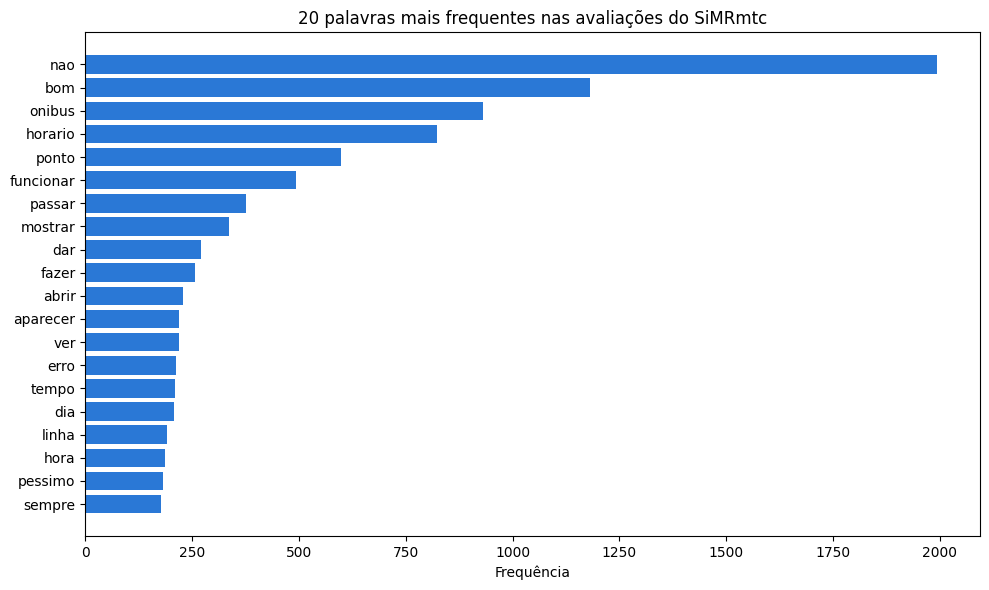

In [33]:
def contar_palavras(serie, n=20):
    return Counter(' '.join(serie).split()).most_common(n)

palavras, freq = zip(*contar_palavras(df_texto['content_limpo']))

plt.figure(figsize=(10, 6))
plt.barh(palavras[::-1], freq[::-1], color="#2a78d6")
plt.title('20 palavras mais frequentes nas avaliações do SiMRmtc')
plt.xlabel('Frequência')
plt.tight_layout()
plt.savefig('palavras_frequentes.png', dpi=150, bbox_inches='tight')
plt.show()

Comparando avaliações de 1★ (o que irrita) e de 5★ (o que agrada).

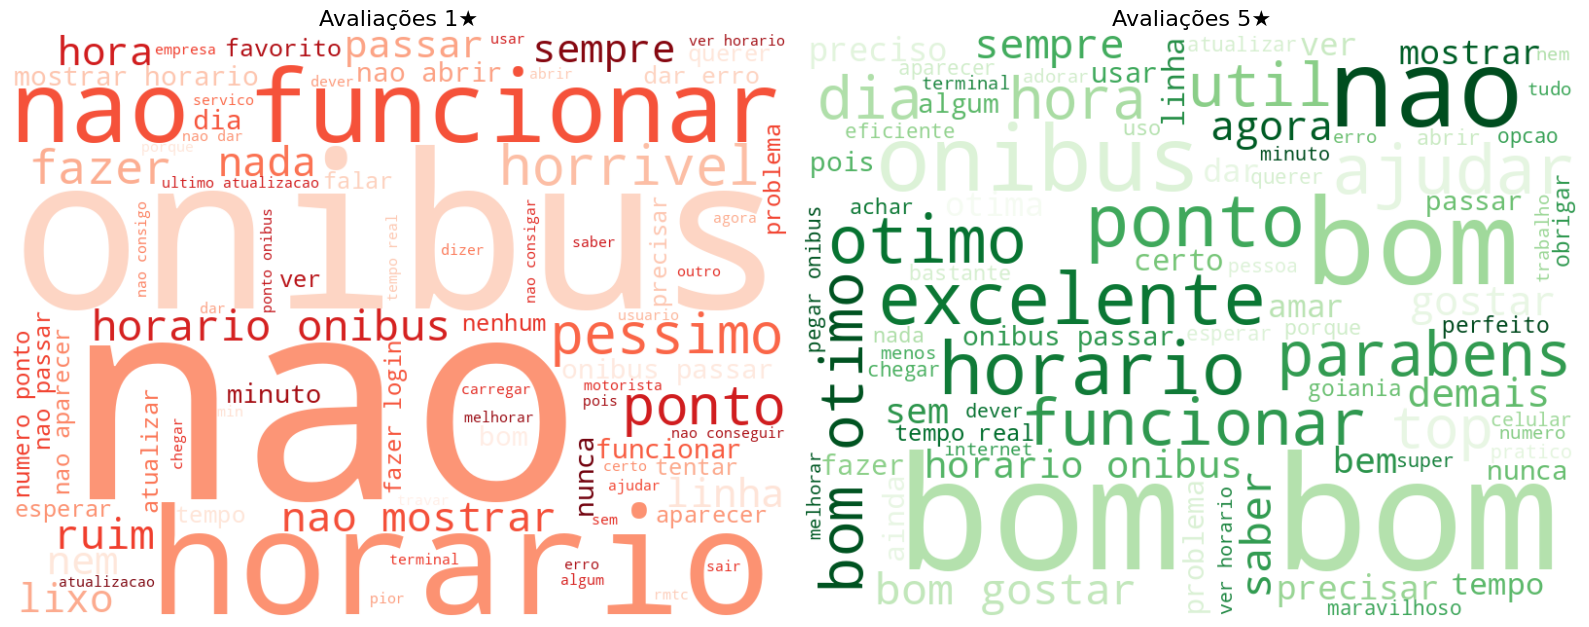

In [34]:
negativas = ' '.join(df_texto.loc[df_texto['score'] == 1, 'content_limpo'])
positivas = ' '.join(df_texto.loc[df_texto['score'] == 5, 'content_limpo'])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, texto, titulo, cor in [
    (axes[0], negativas, 'Avaliações 1★', 'Reds'),
    (axes[1], positivas, 'Avaliações 5★', 'Greens')
]:
    nuvem = WordCloud(width=800, height=600, background_color='white',
                      colormap=cor, max_words=80,
                      normalize_plurals=False,   # não corta o "s" final ("onibus" não vira "onibu")
                      collocations=True          # mantém pares de palavras ("nao funciona")
                      ).generate(texto)
    ax.imshow(nuvem, interpolation='bilinear')
    ax.set_title(titulo, fontsize=16)
    ax.axis('off')

plt.tight_layout()
plt.savefig('nuvens_1x5_estrelas.png', dpi=150, bbox_inches='tight')
plt.show()

Pares de palavras (bigramas) mais comuns nas avaliações de 1★. Eles mostram o **motivo** da reclamação melhor que as palavras soltas.

In [35]:
def top_bigramas(serie, n=15):
    pares = []
    for texto in serie:
        pares.extend(ngrams(texto.split(), 2))
    return Counter(pares).most_common(n)

pd.DataFrame(top_bigramas(df_texto.loc[df_texto['score'] == 1, 'content_limpo']),
             columns=['bigrama', 'frequência'])

,bigrama,frequência
0,"(nao, funcionar)",170
1,"(horario, onibus)",112
2,"(nao, mostrar)",105
3,"(mostrar, horario)",86
4,"(nao, abrir)",86
5,"(onibus, passar)",81
6,"(dar, erro)",68
7,"(nao, passar)",59
8,"(onibus, nao)",57
9,"(nao, aparecer)",51


## Conclusões parciais

<!-- Revise com as suas palavras -->
- **Reclamações:** informação de horário que não aparece ou está errada, falhas técnicas do app ("não funciona", "não abre", "erro") e ônibus que não passa no ponto.
- **Elogios:** utilidade da informação em tempo real ("útil", "ajuda", "prático").
- "Ônibus" e "horário" aparecem nos dois lados: são o **tema** do app, não o sentimento.

## Limitações
- Erros de digitação não foram corrigidos.
- Quem avalia na Play Store não representa todos os usuários do transporte.

## Próximos passos
- Evolução da nota ao longo do tempo e por versão do app
- Bag of Words e TF-IDF
- Análise de sentimentos e BERT